In [1]:
%run manage_tables

StatementMeta(, 11d86f1b-d522-407d-b8a7-e2804679769f, 8, Finished, Available, Finished, True)

In [2]:
from pyspark.sql.functions import *

StatementMeta(, 11d86f1b-d522-407d-b8a7-e2804679769f, 9, Finished, Available, Finished, False)

In [3]:
TABLE_BASE_NAME = "OpenAQ_measurements"
OPENAQ_TABLE_TYPES = ["hours", "days"]

def read_openaq(table_type):
    table_name = f"{TABLE_BASE_NAME}_{table_type}"
    return read_table(table_name, "Bronze_lakehouse")

hours_df = read_openaq("hours")
days_df = read_openaq("days")

StatementMeta(, 11d86f1b-d522-407d-b8a7-e2804679769f, 10, Finished, Available, Finished, False)

In [4]:
def normalize_column_names(df):
    return df.toDF(*[column.replace(".", "_") for column in df.columns])

hours_df = normalize_column_names(hours_df)
days_df = normalize_column_names(days_df)

StatementMeta(, 11d86f1b-d522-407d-b8a7-e2804679769f, 11, Finished, Available, Finished, False)

In [6]:
def inspect_df(df, name):
    print(f"{name}:")
    print(f"num of rows: {df.count()}")
    df.printSchema()
    display(df.limit(5))

inspect_df(hours_df, "hours")
inspect_df(days_df, "days")

StatementMeta(, 11d86f1b-d522-407d-b8a7-e2804679769f, 13, Finished, Available, Finished, False)

hours:
num of rows: 2858414
root
 |-- id: long (nullable = true)
 |-- name: string (nullable = true)
 |-- sensors_id: long (nullable = true)
 |-- sensors_name: string (nullable = true)
 |-- sensors_parameter_id: long (nullable = true)
 |-- sensors_parameter_name: string (nullable = true)
 |-- sensors_parameter_units: string (nullable = true)
 |-- sensors_parameter_displayName: string (nullable = true)
 |-- coordinates_latitude: double (nullable = true)
 |-- coordinates_longitude: double (nullable = true)
 |-- datetimeFirst_utc: timestamp (nullable = true)
 |-- datetimeFirst_local: string (nullable = true)
 |-- datetimeLast_utc: timestamp (nullable = true)
 |-- datetimeLast_local: string (nullable = true)
 |-- period: string (nullable = true)
 |-- measurement_value: double (nullable = true)
 |-- measurement_flagInfo_hasFlags: boolean (nullable = true)
 |-- measurement_period_label: string (nullable = true)
 |-- measurement_period_interval: string (nullable = true)
 |-- measurement_perio

SynapseWidget(Synapse.DataFrame, 068cc90e-18f8-49cf-a4c0-4f91dcc92051)

days:
num of rows: 190742
root
 |-- id: long (nullable = true)
 |-- name: string (nullable = true)
 |-- sensors_id: long (nullable = true)
 |-- sensors_name: string (nullable = true)
 |-- sensors_parameter_id: long (nullable = true)
 |-- sensors_parameter_name: string (nullable = true)
 |-- sensors_parameter_units: string (nullable = true)
 |-- sensors_parameter_displayName: string (nullable = true)
 |-- coordinates_latitude: double (nullable = true)
 |-- coordinates_longitude: double (nullable = true)
 |-- datetimeFirst_utc: timestamp (nullable = true)
 |-- datetimeFirst_local: string (nullable = true)
 |-- datetimeLast_utc: timestamp (nullable = true)
 |-- datetimeLast_local: string (nullable = true)
 |-- period: string (nullable = true)
 |-- measurement_value: double (nullable = true)
 |-- measurement_flagInfo_hasFlags: boolean (nullable = true)
 |-- measurement_period_label: string (nullable = true)
 |-- measurement_period_interval: string (nullable = true)
 |-- measurement_period_

SynapseWidget(Synapse.DataFrame, 0fc4fbfc-76c9-4f0b-8828-e59ca2e9c4a7)

In [7]:
def show_value_statistics(df):
    df.groupBy("sensors_parameter_id", "sensors_parameter_name", "sensors_parameter_units")\
    .agg(count("*").alias("row_count"),
        min("measurement_value").alias("min_value"),
        max("measurement_value").alias("max_value"),
        avg("measurement_value").alias("avg_value"))\
    .orderBy("sensors_parameter_id").show(truncate=False)

show_value_statistics(hours_df)
show_value_statistics(days_df)

StatementMeta(, 11d86f1b-d522-407d-b8a7-e2804679769f, 14, Finished, Available, Finished, False)

+--------------------+----------------------+-----------------------+---------+---------+---------+--------------------+
|sensors_parameter_id|sensors_parameter_name|sensors_parameter_units|row_count|min_value|max_value|avg_value           |
+--------------------+----------------------+-----------------------+---------+---------+---------+--------------------+
|1                   |pm10                  |µg/m³                  |76731    |0.0      |443.0    |13.05527278360469   |
|2                   |pm25                  |µg/m³                  |758862   |-9.1     |816.0    |8.519453718311487   |
|7                   |no2                   |ppm                    |135785   |0.0      |0.236    |0.016892219317301713|
|8                   |co                    |ppm                    |136631   |0.0      |5.4      |0.32380301688490004 |
|9                   |so2                   |ppm                    |135000   |0.0      |0.047    |1.786296296296314E-4|
|10                  |o3        

StatementMeta(, 11d86f1b-d522-407d-b8a7-e2804679769f, 75, Finished, Available, Finished, False)

+-------+-----------------+
|summary|measurement_value|
+-------+-----------------+
|  count|           111996|
|    min|           -0.001|
|    25%|            0.011|
|    50%|            0.019|
|    75%|            0.033|
|    90%|            0.055|
|    95%|            0.075|
|    99%|            0.135|
|  99.9%|            0.277|
|    max|            0.655|
+-------+-----------------+

+-------+-----------------+
|summary|measurement_value|
+-------+-----------------+
|  count|             5294|
|    min|           5.0E-5|
|    25%|           0.0141|
|    50%|           0.0219|
|    75%|           0.0332|
|    90%|           0.0486|
|    95%|           0.0626|
|    99%|           0.0974|
|  99.9%|            0.163|
|    max|              0.4|
+-------+-----------------+



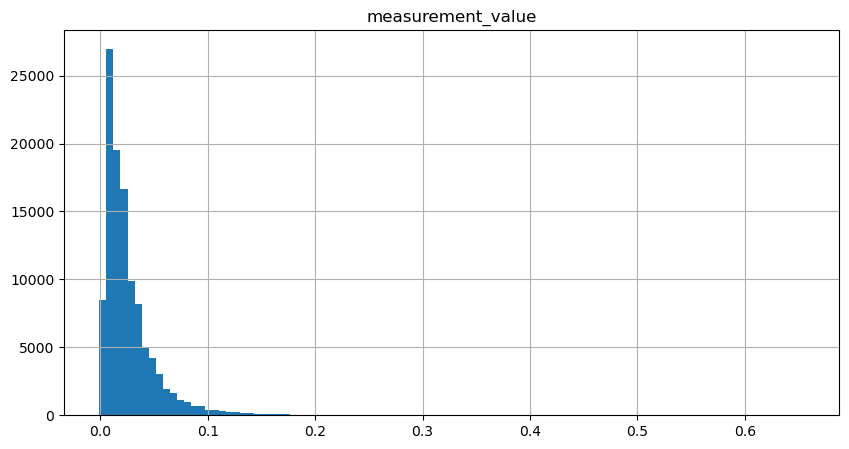

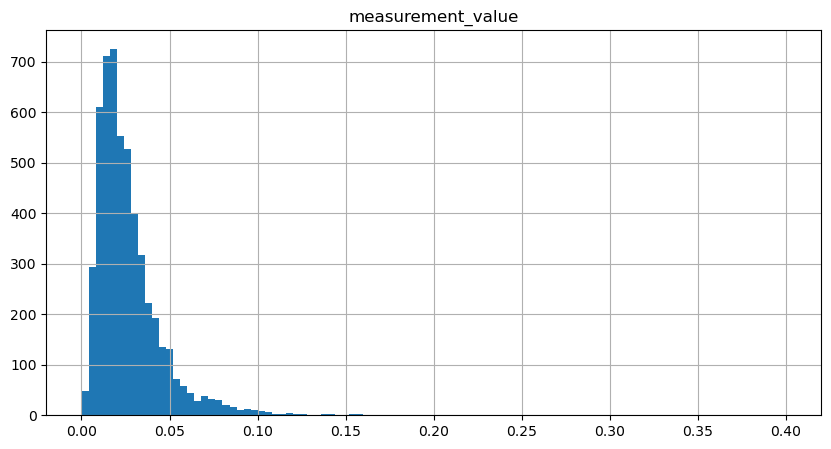

In [68]:
def show_value_distribution(df, parameter_name):
    parameter_df = df.filter(col("sensors_parameter_name") == parameter_name)
    parameter_df.select("measurement_value")\
        .summary("count", "min", "25%", "50%", "75%", "90%", "95%", "99%", "99.9%", "max").show()
    parameter_df.select("measurement_value").toPandas().hist(bins=100, figsize=(10, 5))

show_value_distribution(hours_df, "nox")
show_value_distribution(days_df, "nox")

In [29]:
hours_df.filter(col("sensors_parameter_name") == "pm25")\
        .orderBy(col("measurement_value").desc())\
        .select("sensors_parameter_name", 
            "measurement_value",
            "measurement_period_datetimeFrom_local",
            "coordinates_latitude",
            "coordinates_longitude")\
        .limit(5).show()

StatementMeta(, 11d86f1b-d522-407d-b8a7-e2804679769f, 36, Finished, Available, Finished, False)

+----------------------+-----------------+-------------------------------------+--------------------+---------------------+
|sensors_parameter_name|measurement_value|measurement_period_datetimeFrom_local|coordinates_latitude|coordinates_longitude|
+----------------------+-----------------+-------------------------------------+--------------------+---------------------+
|                  pm25|            816.0|                 2025-08-10T17:00:...|        40.718438547|          -73.8016837|
|                  pm25|            787.0|                 2025-10-03T22:00:...|            40.81405|            -74.21782|
|                  pm25|            678.0|                 2026-05-22T19:00:...|              40.585|              -74.238|
|                  pm25|            651.0|                 2025-10-05T23:00:...|            40.81405|            -74.21782|
|                  pm25|            614.0|                 2025-10-03T23:00:...|            40.81405|            -74.21782|
+-------

In [30]:
hours_df.groupBy("measurement_flagInfo_hasFlags").count().show()

StatementMeta(, 11d86f1b-d522-407d-b8a7-e2804679769f, 37, Finished, Available, Finished, False)

+-----------------------------+-------+
|measurement_flagInfo_hasFlags|  count|
+-----------------------------+-------+
|                         true|  28714|
|                        false|2829700|
+-----------------------------+-------+



In [36]:
display(hours_df.filter(col("measurement_flagInfo_hasFlags")).select("sensors_parameter_name", "measurement_value", "measurement_flagInfo_hasFlags").limit(25)\
.union(hours_df.filter(~col("measurement_flagInfo_hasFlags")).select("sensors_parameter_name", "measurement_value", "measurement_flagInfo_hasFlags").limit(25)))

StatementMeta(, 11d86f1b-d522-407d-b8a7-e2804679769f, 43, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 381225dd-8103-4a7e-87e3-5e7f7ec15d41)

In [38]:
hours_df.filter(col("sensors_parameter_name") == "pm25")\
    .groupBy("measurement_flagInfo_hasFlags")\
    .agg(min("measurement_value").alias("min_value"),
        max("measurement_value").alias("max_value")
    ).show()

StatementMeta(, 11d86f1b-d522-407d-b8a7-e2804679769f, 45, Finished, Available, Finished, False)

+-----------------------------+---------+---------+
|measurement_flagInfo_hasFlags|min_value|max_value|
+-----------------------------+---------+---------+
|                         true|     -1.6|     37.1|
|                        false|     -9.1|    816.0|
+-----------------------------+---------+---------+



In [53]:
display(hours_df.filter(col("measurement_flagInfo_hasFlags") & (col("measurement_value") > 0)).limit(1))

StatementMeta(, 11d86f1b-d522-407d-b8a7-e2804679769f, 60, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, e7365772-58dd-4f0c-99e1-9c1b10cc7abd)

In [47]:
import requests

url = "https://api.openaq.org/v3/sensors/1534/flags"
headers = {"X-API-Key": "b2f97c1f3b75cd54f4374a54f0dd3c98f67bf3a2e4aa71c771db5bdced89f8ff"}
params = {"datetime_from": "2016-03-19T07:00:00Z",
    "datetime_to": "2016-03-19T08:00:00Z"}
response = requests.get(url, headers=headers, params=params)
print(response.json())

StatementMeta(, 11d86f1b-d522-407d-b8a7-e2804679769f, 54, Finished, Available, Finished, False)

{'meta': {'name': 'openaq-api', 'website': '/', 'page': 1, 'limit': 100, 'found': 1}, 'results': [{'locationId': 857, 'flagType': {'id': 4, 'label': 'Limits exceeded', 'level': 'ERROR'}, 'datetimeFrom': {'utc': '2016-03-19T07:00:00Z', 'local': '2016-03-19T03:00:00-04:00'}, 'datetimeTo': {'utc': '2016-03-19T08:00:00Z', 'local': '2016-03-19T04:00:00-04:00'}, 'sensorIds': [], 'note': '1 measurements exceeded limits (min: -1.6000, max: -1.6000)'}]}


In [54]:
params = {"datetime_from": "2016-03-12T12:00:00Z",
    "datetime_to": "2016-03-12T13:00:00Z"}
response = requests.get("https://api.openaq.org/v3/sensors/1534/flags", headers=headers, params=params)
print(response.json())

StatementMeta(, 11d86f1b-d522-407d-b8a7-e2804679769f, 61, Finished, Available, Finished, False)

{'meta': {'name': 'openaq-api', 'website': '/', 'page': 1, 'limit': 100, 'found': 1}, 'results': [{'locationId': 857, 'flagType': {'id': 4, 'label': 'Limits exceeded', 'level': 'ERROR'}, 'datetimeFrom': {'utc': '2016-03-12T10:00:00Z', 'local': '2016-03-12T05:00:00-05:00'}, 'datetimeTo': {'utc': '2016-03-12T13:00:00Z', 'local': '2016-03-12T08:00:00-05:00'}, 'sensorIds': [], 'note': '3 measurements exceeded limits (min: -4.6000, max: -0.6000)'}]}


In [44]:
(hours_df.filter(col("sensors_parameter_name") == "temperature")
    .select("sensors_parameter_units")
.union(days_df.filter(col("sensors_parameter_name") == "temperature")
    .select("sensors_parameter_units"))
).groupBy("sensors_parameter_units").count().show()

StatementMeta(, 11d86f1b-d522-407d-b8a7-e2804679769f, 51, Finished, Available, Finished, False)

+-----------------------+------+
|sensors_parameter_units| count|
+-----------------------+------+
|                      c|309541|
+-----------------------+------+



In [56]:
display(hours_df.filter((col("sensors_parameter_name") == "temperature") & (col("measurement_value") == 52.9)))

StatementMeta(, 11d86f1b-d522-407d-b8a7-e2804679769f, 63, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 53132c29-5bc0-4bd1-9112-263575bc9a2d)